# RQ1 — Organization co-occurrence network (Network Topology / Centrality)

**Question.** How are organizations positioned relative to each other in the post-9/11 records archive?
**Hypothesis 1 (as stated by the team, tested — not assumed).** Municipal regulatory agencies and private real-estate entities have higher degree and betweenness centrality than public-health advocacy groups.

**What an edge means here.** Two organizations are linked when both are *named on the same page*. That is co-occurrence in the archive — not proof of communication, collaboration, influence or power.

**Data.** NYC 9/11 document archive (<https://911records.org>; original PDFs on the City portal `sept11documents.cityofnewyork.us`), scraped by the team into `data/final/*.parquet` in <https://github.com/dapivei/nyc-911-records-analysis>.

**Workflow.** Pandas: clean and build edges → NetworkX: degree and betweenness → descriptive group comparison → frequency check → sensitivity checks (without multi-organization pages; study window only; hand-confirmed real-estate entities only) → Matplotlib figures → independent verification.

**Prerequisites**
* Python ≥ 3.11 with `pandas`, `pyarrow`, `networkx`, `scipy` (used by the network layout), `matplotlib` (tested: Anaconda, Python 3.14, pandas 3.0, networkx 3.6).
* `data/processed/` exists: run `python -m src.processing.clean` from the repo root (needs the real `data/final/*.parquet`, i.e. `git lfs pull`).
* Run this notebook top to bottom (≈ 2 minutes). The same pipeline runs headless with `python -m src.analysis.network.run` (writes the tables and figures used below).

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":          # run from the repo root so `src` and `data/` resolve
    os.chdir(Path.cwd().parent)
import pandas as pd, numpy as np
from IPython.display import Image, display
from src.analysis.network import build, checks, classify, figures, metrics, pipeline, robustness, settings, verify
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70); pd.set_option("display.max_columns", 30)
assert (settings.PROCESSED / "entity_mentions.parquet").exists(), "run `python -m src.processing.clean` first"
print("working dir:", Path.cwd())

working dir: /Users/devin/Documents/nyc-911-records-analysis


## 1. Data checks
Tables (all from `data/processed/`): `entity_mentions` (entity → doc_id, page) joins `pages` on `(doc_id, page)` and `documents` on `doc_id`; `entities` gives names and the cleaned `entity_id`.

In [2]:
prep = pipeline.prepare(with_advocacy=True, keep_text=True)
t = prep.tables
{k: v.shape for k, v in t.items()}

{'documents': (64541, 11),
 'pages': (230315, 6),
 'entities': (15915, 12),
 'entity_mentions': (649168, 6)}

In [3]:
checks.key_checks(t)

,check,count
0,documents: duplicate doc_id,0
1,"pages: duplicate (doc_id, page)",0
2,"entities: duplicate (source_type, slug)",0
3,"entity_mentions: duplicate (source_type, slug, doc_id, page)",0
4,"entity_mentions: duplicate (entity_type, entity_id, doc_id, page) ...",9475
5,entity_mentions: missing entity_id,0
6,entity_mentions: doc_id not in documents,0
7,"entity_mentions: (doc_id, page) not in pages",0
8,entity_id values shared by >1 entity_type,109


* Keys are clean and every mention joins to a document and a page.
* After `clean.py` merges name variants into one `entity_id`, 9,475 mention rows repeat a (type, id, doc, page) — so mentions are **deduplicated per node and page** before pairs are formed.
* 109 `entity_id`s are shared across entity types (mostly contractor/lab, some contractor/signatory), so a node key must include the type: here `agency:<id>` / `company:<id>` (contractor and lab with the same normalised name = one company).

In [4]:
checks.entity_type_overview(t)

,entity_type,entity_ids,mention_pages,docs,in_network
0,address,6306,67864,12162,False
1,agency,30,90746,17547,True
2,contractor,5897,40241,9822,True
3,lab,1121,24142,4620,True
4,signatory,1658,4591,2658,False
5,substance,53,412109,47932,False


**What the entity types are** (inspected by hand, notebook author's reading):
* `agency` — 30 organizations after the team's hand map (`src/processing/agency_map.py`), with a level (city / state / federal / regional / private / nonprofit). Most reliable.
* `contractor`, `lab` — machine-extracted company names. Includes real companies (ATC Associates, Silverstein Properties) but also many fragments ("Services Inc.", "Final Laboratory", "Acting Corp.").
* `signatory` — people and role labels ("Official signatory", "approved-by"): **excluded** (not organizations).
* `address`, `building`, `substance` — not organizations: **excluded**.

In [5]:
dates = checks.date_coverage(prep.om, t["documents"])
print(json.dumps(dates, indent=1, default=str))

{
 "docs_with_org": 18998,
 "docs_dated": 16623,
 "share_dated_of_all": 0.8749868407200758,
 "docs_in_study_window": 14121,
 "share_in_window_of_all": 0.7432887672386567,
 "share_in_window_of_dated": 0.8494856524093124,
 "docs_before_2001_09_11": 2493,
 "docs_1997_2000": 1969,
 "docs_before_1997": 127,
 "docs_after_2009": 9,
 "share_2001_2002_of_dated": 0.7866811044937737,
 "doc_date_min": "1908-05-28 00:00:00",
 "doc_date_max": "2013-11-01 00:00:00",
 "date_precision_counts": {
  "day": 13262,
  "month": 2720,
  "NaN": 2375,
  "year": 641
 },
 "date_fix_counts": {
  "raw date matching title": 9440,
  "title date (no raw date)": 3034,
  "raw date (no title date)": 2724,
  "no date": 2375,
  "raw date (conflicts with title)": 1001,
  "title date (raw date implausible)": 424
 }
}


**Date coverage (denominators stated).** Of the 18,998 documents that name a kept organization, 16,623 (87.5%) have a `doc_date`. 14,121 fall in the study window 2001-09-11 to 2009-12-31: 74.3% of all 18,998, or 85.0% of the dated ones. 78.7% of dated documents are from 2001–2002. **2,493 dated documents (15.0%) are from before 11 September 2001** — mostly 1997–2000 (1,969), plus 127 before 1997 and 9 after 2009 (latest 2013). 641 dates are year-only and 2,720 month-only.

In [6]:
# extreme dates, for manual review: is the date the document's own, or a parse / OCR error?
checks.date_extremes(prep.om, t["documents"])[["end", "doc_id", "doc_date", "date_fix", "title", "doc_date_raw", "box"]]

,end,doc_id,doc_date,date_fix,title,doc_date_raw,box
0,earliest,NYC-WTC_000167646,1908-05-28,raw date (no title date),"Memo to commence reconstruction at 7 WTC for MOEM, May","May 28, 1908",7DCAS
1,earliest,NYC-WTC_000167680,1908-05-28,raw date (conflicts with title),"Contract registration cover sheet, July 1995","May 28, 1908",7DCAS
2,earliest,NYC-WTC_000165482,1982-03-09,raw date (no title date),"Organizational advisory board listing, March 1982","March 9, 1982 1 TO: MA.GDI FARAG, P.E., CHIEF, ENGINEERING REVIEW ...",DEP Box 44
3,earliest,NYC-WTC_000165835,1983-11-23,raw date (no title date),"Internal sewer capacity memo, 10th Ave Tunnel, Nov 1983","November 23, 1983",DEP Box 44
4,earliest,NYC-WTC_000165265,1985-03-01,title date (no raw date),"DEP memo on Lincoln Tunnel bridge repair drawings, March 1985",NaN,DEP Box 44
5,earliest,NYC-WTC_000165038,1985-04-01,title date (no raw date),"PVC drainage connection approval memo, Apr 1985",NaN,DEP Box 44
6,earliest,NYC-WTC_000165035,1985-04-01,raw date matching title,"Convention center drainage connection approval, Apr 1985","April 1, 1985",DEP Box 44
7,earliest,NYC-WTC_000165316,1986-01-01,title date (no raw date),"Letter with comments on WTC tunnel drawings, January 1986",NaN,DEP Box 44
8,earliest,NYC-WTC_000165756,1986-08-01,title date (no raw date),"Telephone conversation memo, Aug 1986",NaN,DEP Box 44
9,earliest,NYC-WTC_000165753,1986-08-01,title date (no raw date),"Telephone conversation memorandum, Parsons Brinckerhoff, Aug 1986",NaN,DEP Box 44


**Extreme dates, checked by hand.**
* **Stored range: 1908-05-28 to 2013-11-01** (the `doc_date` values from `src/processing`, not changed here). Excluding the two suspected errors below, the range is 1982–2013.
* The two **1908** documents are **suspected date errors** (manual judgement): the same Office of Contracts cover sheet addressed to "7 World Trade Company, L.P." (box 7DCAS), with "DATE: May 28, 1908" in the extracted page text; one of the two titles says July 1995. The original PDFs were not checked, so we do not know whether "1908" is printed or comes from text extraction, and no corrected date is assumed. The cleaning rules keep a raw date unless it is missing, on or before 9/11 for a post-9/11 title, or more than a year after the title, so these were kept.
* The other 8 of the 10 earliest (1982–1986) are sewer, drainage and tunnel memos from DEP Box 44. Their titles give the same month and year, so they look like genuine older material. The remaining 117 pre-1997 documents were not checked one by one.
* The latest (2011–2013) are asbestos lab reports, chain-of-custody forms and a subpoena receipt, with dates from or matching the title: plausible.
* The 18,998 documents fall into four non-overlapping periods: 14,121 study window, 2,493 before 11 September 2001, 9 after 2009, 2,375 undated.
* **The main network is not filtered by date.** It pools every document, dated or not, so it describes the released archive, not only the post-9/11 response period. Section 3 shows how much of its pair evidence comes from each period; section 5 rebuilds the network from study-window documents only.

In [7]:
checks.source_bias(prep.om, t["documents"]).head(8)

,agency,docs,share
0,"Environmental Protection, Dept. of",11830,0.622697
1,"Education, Dept. of",2916,0.153490
2,"Citywide Administrative Services, Dept. of",2145,0.112907
3,"Design and Construction, Dept. of",863,0.045426
4,"Health and Mental Hygiene, Dept. of",293,0.015423
5,Law Department,271,0.014265
6,Fire Department,166,0.008738
7,School Construction Authority,138,0.007264


**Archive bias.** ~62% of the documents that name any organization come from DEP's own files. Any DEP-centred structure partly reflects *whose files were released*, not only who was central.

In [8]:
checks.unit_size_distribution(prep.om)

,unit,units_with_org,units_with_2plus,median_orgs,p90,p99,p99_of_2plus,max,pairs_total,share_pairs_from_top1pct_units
0,page,71165,30558,1.0,3.0,5.0,7.0,23,99758,0.258435
1,doc,18998,13310,2.0,5.0,12.0,14.0,312,236361,0.702028


**Choice of co-occurrence unit.** At the *document* level, the top 1% largest documents generate ~70% of all organization pairs (one document names 312 organizations). At the *page* level the median page names 1 organization, p99 of multi-organization pages is 7, and the top 1% produce ~26% of pairs. → **Page co-occurrence is the main analysis**; document co-occurrence is kept only as a comparison.

In [9]:
checks.largest_units(prep.om, t["documents"], "page", 12)[["doc_id", "page", "n_orgs", "title"]]

,doc_id,page,n_orgs,title
0,NYC-WTC_000156544,5,23,"DEP inspection form header, Apr 23 2002"
1,NYC-WTC_000162145,7,23,"List of WTC-affected buildings with ownership information, April 2002"
2,NYC-WTC_000162145,9,23,"List of WTC-affected buildings with ownership information, April 2002"
3,NYC-WTC_000162145,11,23,"List of WTC-affected buildings with ownership information, April 2002"
4,NYC-WTC_000135642,5,22,Exterior CleanUp License survey list for Barclay Street
5,NYC-WTC_000162145,10,21,"List of WTC-affected buildings with ownership information, April 2002"
6,NYC-WTC_000156592,10,21,"WTC environmental records page, undated"
7,NYC-WTC_000135642,7,21,Exterior CleanUp License survey list for Barclay Street
8,NYC-WTC_000156347,2,21,"DEP Bureau of [name] document header, BUILDINGS LISTS folder"
9,NYC-WTC_000156544,4,21,"DEP inspection form header, Apr 23 2002"


The largest pages are a mix: building / property lists, DEP inspection-form headers and at least one letter (Law Department, row 11). A page that names many organizations creates many edges at once whatever its type, so the sensitivity check below drops **multi-organization pages** (more than 7 organizations, the p99 of pages with ≥ 2). This is a rule about page *size*; it does not classify document types.

### 1b. Manual spot check against the page text
Five random pages with 2–4 organizations (seeded) plus the largest page; the names listed should be visible in the text.

In [10]:
pages_idx = t["pages"].set_index(["doc_id", "page"])
names = prep.node_info.set_index("node_id")["name"]
sizes = build.unit_sizes(prep.om, "page")
sample = list(sizes[(sizes >= 2) & (sizes <= 4)].sample(5, random_state=settings.SEED).index) + [sizes.idxmax()]
for doc, page in sample:
    ids = prep.om.query("doc_id == @doc and page == @page")["node_id"]
    txt = " ".join(str(pages_idx.loc[(doc, page), "text"]).split())
    print(f"--- {doc} p.{page} | {t['documents'].set_index('doc_id').loc[doc, 'title']}")
    print("    orgs:", "; ".join(names[i] for i in ids))
    print("    text:", txt[:400], "...\n")

--- NYC-WTC_000104027 p.211 | Ambient air sampling report for 105 Duane Street, Feb 2002
    orgs: U.S. EPA; Atc Associates Inc.; Atc Environmental Inc.
    text: IJ ATC Environmental, Inc. 104 East 25th Street New York, New York 10010 ATC Associates Inc. 104 East 25th Street New York, NY 10010 Approved N.Y. State ELAP #10879 ACCREDITED NVLAP Lab Code # 1187 Report Date: 10/26/01 ASBESTOS FIBER ANALYSIS BY TRANSMISSION ELECTRON MICROSCOPY (TEM) With Fiber Identification by Selected-Area Electron Diffraction (SAED) and Energy-Dispersive X-RAY Spectroscopy (E ...

--- NYC-WTC_000199010 p.2 | IAQ Report Cover Letter, PS89M, May 2002
    orgs: U.S. EPA; Air-conditioning Engineers
    text: Mr. Bernard P. Orlan May 9, 2002 Indoor Air Quality Assessment Page 2 P. S. 89M ATC Project No. 15-19125-0297 presented in this report should be used by the BOE as a guide to assess the need for further improvements in current indoor air quality control activities. EVALUATION CRITERIA Currently, there ar

## 2. Nodes, merges, exclusions and classification
Rules (`src/analysis/network/classify.py`, `settings.py`), all fixed before metrics were computed:
1. **Merges** of OCR / prefix variants clean.py left apart (`COMPANY_MERGES`, each listed with a reason), e.g. "Landlord Silverstein Properties" → Silverstein Properties. Candidates were found by the rule *id = 1–2 token prefix + another id*, then checked by eye; the automatic rule alone would mis-merge (e.g. "PSC Analytical Services" → "Analytical Services").
2. **Artifacts** — job titles / phrases (`ARTIFACT_IDS`) and names with no distinctive word (`is_generic_name`).
3. **Support** — a company must appear in ≥ 2 documents (`MIN_NODE_DOCS`).
4. **Groups** — agencies from the team's agency map plus an a-priori list of municipal *regulators* (DEP, DOHMH, DOB, HPD); companies by manual entries (`MANUAL_GROUPS`, with basis) or conservative keywords; everything else `other_unknown`.

In [11]:
prep.candidates["excluded_reason"].fillna("KEPT").str.split(":").str[0].value_counts()

excluded_reason
support                               4928
KEPT                                  1652
generic name (no distinctive word)     332
artifact                                24
Name: count, dtype: int64

In [12]:
prep.candidates[prep.candidates.excluded_reason.notna()].head(15)[["node_id", "name", "n_docs", "excluded_reason"]]

,node_id,name,n_docs,excluded_reason
16,company:environmental-laboratory,Environmental Laboratory,550,generic name (no distinctive word)
20,company:acting,Acting Corp.,461,artifact: word 'Acting' + Corp.
30,company:sample-analysis-laboratory,Sample Analysis Laboratory,285,generic name (no distinctive word)
39,company:accredited-laboratory,Accredited Laboratory,207,generic name (no distinctive word)
42,company:health-environmental-laboratory,Health Environmental Laboratory,193,generic name (no distinctive word)
44,company:final-laboratory,Final Laboratory,186,generic name (no distinctive word)
46,company:distribution-laboratory,Distribution Laboratory,150,generic name (no distinctive word)
50,company:national-voluntary-laboratory,National Voluntary Laboratory,143,"artifact: NVLAP accreditation program name, not a lab"
51,company:nvlap-laboratory,Nvlap Laboratory,139,"artifact: NVLAP accreditation program name, not a lab"
52,company:new-york-laboratory,New York Laboratory,128,generic name (no distinctive word)


In [13]:
cls = prep.node_info
pd.crosstab(cls["group"], cls["review_status"], margins=True)

review_status,curated (agency_map.py + a-priori regulator list),manual,manual (uncertain),rule (unreviewed),unclassified,All
group,,,,,,
city_other,10,3,0,0,0,13
consultant_contractor_lab,0,6,1,578,0,585
municipal_regulatory,4,0,0,0,0,4
nonprofit_relief,2,0,0,0,0,2
other_unknown,0,5,0,0,904,909
private_real_estate,0,10,10,99,0,119
private_utility,2,0,0,0,0,2
public_health_advocacy,0,4,0,0,0,4
state_federal_regional,12,5,1,0,0,18


In [14]:
cls.query("group == 'private_real_estate'").nlargest(20, "n_docs")[["entity_id", "name", "n_docs", "basis", "review_status"]]

,entity_id,name,n_docs,basis,review_status
13,silverstein-properties,Silverstein Properties Inc.,790,WTC site leaseholder / 7 WTC developer,manual
24,rockrose-development,Rockrose Development Corp.,345,residential developer & landlord (Lower Manhattan),manual
58,duane-street-associates,Duane Street Associates,44,building-owning partnership named for its street,manual (uncertain)
65,century-realty,Century Realty Inc.,38,'Realty' in name,manual
66,maiden-lane-associates,Maiden Lane Associates LLC,38,building-owning partnership named for its street,manual (uncertain)
68,gateway-plaza-management,Gateway Plaza Management Corp.,35,manager of Gateway Plaza residential complex (BPC),manual
69,newmark-and,Newmark And Co.,34,Newmark & Co. Real Estate (see newmark-and-real-estate),manual (uncertain)
79,broadway-associates,Broadway Associates,31,building-owning partnership named for its street,manual (uncertain)
93,financial-district-associates,Financial District Associates LLC,24,building-owning partnership,manual (uncertain)
97,cushman-and-wakefield,Cushman And Wakefield Inc.,23,commercial real estate services firm,manual


**Public-health advocacy groups do not exist among the extracted entities.** The agency map's only nonprofits are the Red Cross and the Salvation Army (relief organizations), and no contractor/lab name is an advocacy group. A text search shows the archive *does* name some of them, rarely. For an **exploratory supplement**, four organizations are detected by a fixed name list (`build.ADVOCACY_PATTERNS`). Sierra Club and "Beyond Ground Zero" were dropped after a precision check (all hits unrelated), before any metric was computed.

In [15]:
build.advocacy_nodes(prep.adv)[["node_id", "name", "n_pages", "n_docs"]]

,node_id,name,n_pages,n_docs
0,advocacy:911-environmental-action,9/11 Environmental Action,23,14
1,advocacy:american-lung-association,American Lung Association,20,16
2,advocacy:nrdc,Natural Resources Defense Council,33,21
3,advocacy:nycosh,NYCOSH (NY Committee for Occupational Safety & Health),57,33


## 3. Main network: page co-occurrence among extracted organizations
* undirected (no reliable sender/recipient fields); each page contributes each pair once
* weight = number of distinct pages shared (used for strength and in fig 4)
* every edge is traceable: `outputs/network/edge_evidence_main.parquet` lists (source, target, doc_id, page)
* no self-loops (pairs require source < target); isolates are kept as nodes

In [16]:
main = pipeline.build_network(prep, unit="page")
sup = pipeline.build_network(prep, unit="page", include_advocacy=True)
doc = pipeline.build_network(prep, unit="doc")
stats = pd.DataFrame({"page (main)": main["stats"], "page + advocacy": sup["stats"], "document": doc["stats"]})
print("betweenness:", main["betweenness_info"])
stats

betweenness: {'method': 'exact (Brandes)', 'nodes': 1652, 'edges': 11166, 'seconds': 3.3}


,page (main),page + advocacy,document
nodes,1652.000000,1656.000000,1652.000000
edges,11166.000000,11227.000000,92848.000000
density,0.008188,0.008193,0.068084
components,109.000000,109.000000,19.000000
largest_component_nodes,1500.000000,1504.000000,1628.000000
largest_component_share,0.907990,0.908213,0.985472
isolates,91.000000,91.000000,16.000000
degree_mean,13.518160,13.559179,112.406780
degree_median,5.000000,5.000000,24.000000
degree_max,738.000000,742.000000,1222.000000


Betweenness is **exact** (Brandes algorithm in networkx, cost ≈ O(nodes × edges)): ~1,650 nodes and ~11,000 edges take a few seconds, so no sampling is needed. Degree and betweenness ignore edge weights.

In [17]:
cols = ["name", "group", "n_pages", "n_docs", "degree", "degree_centrality", "strength", "betweenness"]
main["nodes"].nlargest(20, "degree_centrality")[cols]

,name,group,n_pages,n_docs,degree,degree_centrality,strength,betweenness
0,NYC Dept. of Environmental Protection,municipal_regulatory,26158,7759,738,0.447002,21089.0,0.319309
1,U.S. EPA,state_federal_regional,24138,7434,487,0.294973,25911.0,0.167431
2,NYC Dept. of Health and Mental Hygiene,municipal_regulatory,7862,4387,348,0.210781,14397.0,0.072463
5,NIOSH,state_federal_regional,6239,2076,235,0.142338,9729.0,0.062456
8,NYC Dept. of Buildings,municipal_regulatory,2615,1551,221,0.133858,2892.0,0.034792
4,OSHA,state_federal_regional,5254,2084,217,0.131435,8170.0,0.044872
65,Century Realty Inc.,private_real_estate,68,38,180,0.109025,627.0,0.007895
7,NYC Board of Education,city_other,2341,1600,175,0.105996,5348.0,0.018631
16,FDNY,city_other,988,489,173,0.104785,2095.0,0.024432
118,American Stock Exchange Inc.,other_unknown,37,20,156,0.094488,399.0,0.011951


In [18]:
main["nodes"].nlargest(15, "betweenness")[cols]

,name,group,n_pages,n_docs,degree,degree_centrality,strength,betweenness
0,NYC Dept. of Environmental Protection,municipal_regulatory,26158,7759,738,0.447002,21089.0,0.319309
1,U.S. EPA,state_federal_regional,24138,7434,487,0.294973,25911.0,0.167431
2,NYC Dept. of Health and Mental Hygiene,municipal_regulatory,7862,4387,348,0.210781,14397.0,0.072463
5,NIOSH,state_federal_regional,6239,2076,235,0.142338,9729.0,0.062456
4,OSHA,state_federal_regional,5254,2084,217,0.131435,8170.0,0.044872
11,NYC Office of the Mayor,city_other,1534,1043,114,0.069049,2098.0,0.038830
8,NYC Dept. of Buildings,municipal_regulatory,2615,1551,221,0.133858,2892.0,0.034792
6,NYC Office of Emergency Management,city_other,2699,1802,124,0.075106,4224.0,0.030652
22,Port Authority of NY & NJ,state_federal_regional,886,411,114,0.069049,1204.0,0.029551
16,FDNY,city_other,988,489,173,0.104785,2095.0,0.024432


**Are high ranks only frequency?** Compare how often an organization is named with its centrality (Spearman rank correlation, pandas `corr(method="spearman")`).

In [19]:
from src.analysis.network.run import frequency_check, multi_org_share
frequency_check(main["nodes"]).round(3)

,metric,spearman_with_n_pages,nodes
0,degree,0.437,1652
1,strength,0.640,1652
2,betweenness,0.562,1652


Degree is moderately correlated with frequency (ρ ≈ 0.44), betweenness more (ρ ≈ 0.56), strength most (ρ ≈ 0.64). The most central organizations are also the most named (DEP: 26,158 pages); with this correlation we **cannot separate "structurally important" from "recorded often"**.

Where does each group's pair evidence come from? Share of evidence rows from multi-organization pages (> 7 organizations):

In [20]:
cutoff = build.large_unit_cutoff(prep.om, "page")
multi_org_share(main, prep, cutoff).round(3)

,group,share,evidence_rows
1,consultant_contractor_lab,0.053,37940
7,state_federal_regional,0.059,57435
2,municipal_regulatory,0.070,39165
6,private_utility,0.172,780
0,city_other,0.180,21361
3,nonprofit_relief,0.260,592
5,private_real_estate,0.532,14277
4,other_unknown,0.604,27966


53% of the pair evidence behind real-estate nodes comes from multi-organization pages, vs 7% for municipal regulators.

In [21]:
# the network is not filtered by date: pair evidence by the period of its document
checks.evidence_by_period(main["evidence"], t["documents"]).round(3)

,period,pair_evidence_rows,share
0,study window,87875,0.881
1,undated,6029,0.060
2,before 2001-09-11,5831,0.058
3,after study window,23,0.000


88.1% of the pair evidence comes from documents in the study window, 5.8% from documents before 11 September 2001, 6.0% from undated documents and 0.02% from after 2009.

## 4. Hypothesis groups: descriptive comparison
**Percentiles are recomputed within each network.** A group's percentile can rise while its raw degree or betweenness falls (other nodes fell more), so raw values and ranks are shown next to the percentiles.

No significance test is reported: nodes of one network are not independent; the municipal-regulator and advocacy groups have 4 nodes each; and the advocacy nodes were found by a different method (text name list), so their recall is not comparable. A p-value would add false precision. Instead: every node's percentile rank, and group n / median / quartiles / min / max.

**Classification sensitivity.** 99 of the 119 real-estate nodes were assigned by a keyword rule and not checked one by one. The views below also show the **10 real-estate nodes confirmed by hand** (`review_status == "manual"`) and the 20 manual ones including 10 marked uncertain.

In [22]:
rob, summary, hyp_nodes, nets = robustness.run(prep)
scen = list(nets)
summary.pivot_table(index="view", columns=["metric", "scenario"], values="median", sort=False).round(1)

metric,pct_degree_centrality,pct_betweenness,pct_degree_centrality,pct_betweenness,pct_degree_centrality,pct_betweenness,pct_degree_centrality,pct_betweenness
scenario,baseline: page co-occurrence,baseline: page co-occurrence,"page, without multi-organization pages (> 7 orgs)","page, without multi-organization pages (> 7 orgs)",document co-occurrence,document co-occurrence,"page, study window only (2001-09-11 to 2009-12-31)","page, study window only (2001-09-11 to 2009-12-31)"
view,,,,,,,,
municipal regulatory,99.8,99.8,99.8,99.8,99.5,99.5,99.8,99.8
private real estate: all,83.6,72.9,50.8,34.5,81.2,68.1,83.8,74.2
"private real estate: manual, incl. uncertain",95.9,94.9,93.1,86.3,95.7,94.8,95.6,94.4
private real estate: manually confirmed,95.3,96.0,93.6,91.2,96.2,96.0,92.0,95.5
public-health advocacy (exploratory),78.3,76.4,94.0,84.5,60.2,66.8,81.8,78.8


In [23]:
# the two 4-node groups, node by node (baseline)
hyp_nodes.query("scenario == @scen[0] and view in ['municipal regulatory', 'public-health advocacy (exploratory)']")[
    ["view", "name", "n_pages", "degree", "betweenness", "rank_degree", "rank_betweenness",
     "pct_degree_centrality", "pct_betweenness"]].round(4)

,view,name,n_pages,degree,betweenness,rank_degree,rank_betweenness,pct_degree_centrality,pct_betweenness
0,municipal regulatory,NYC Dept. of Environmental Protection,26158,742,0.3193,1,1,100.0000,100.0000
1,municipal regulatory,NYC Dept. of Health and Mental Hygiene,7862,352,0.0725,3,3,99.8792,99.8792
2,municipal regulatory,NYC Dept. of Buildings,2615,221,0.0346,5,7,99.7585,99.6377
3,municipal regulatory,NYC Dept. of Housing Preservation and Development,302,45,0.0018,116,86,92.9952,94.8671
153,public-health advocacy (exploratory),9/11 Environmental Action,23,14,0.0003,395,251,75.9058,84.9034
154,public-health advocacy (exploratory),American Lung Association,20,14,0.0000,395,525,75.9058,68.3575
155,public-health advocacy (exploratory),Natural Resources Defense Council,33,18,0.0000,313,521,80.7367,68.5990
156,public-health advocacy (exploratory),NYCOSH (NY Committee for Occupational Safety & Health),57,18,0.0003,313,262,80.7367,84.2391


In [24]:
# the 10 hand-confirmed real-estate nodes are also frequently named: compare page counts
pd.concat([hyp_nodes.query("scenario == @scen[0]").groupby("view")["n_pages"].median().rename("median pages named"),
           hyp_nodes.query("scenario == @scen[0]").groupby("view").size().rename("n")], axis=1)

,median pages named,n
view,,
municipal regulatory,5238.5,4
private real estate: all,5.0,119
"private real estate: manual, incl. uncertain",51.5,20
private real estate: manually confirmed,72.5,10
public-health advocacy (exploratory),28.0,4


## 5. Sensitivity checks
Each scenario rebuilds the network and recomputes every metric and percentile.

**Study window only** (2001-09-11 to 2009-12-31): every mention, including the 4 text-search advocacy groups, is kept only if its document has `in_study_window`; undated documents are dropped. **The node set is fixed** (1,656 nodes as in every variant): nodes with no mention left are isolates with tied lowest ranks, so all variants rank the same nodes. As a check, the percentiles are recomputed within the subset of active nodes below. This check does not rebuild a smaller network: it keeps the full network's metrics and only recomputes the percentiles within the active-node subset. In a rebuilt smaller network, degree and the unnormalised betweenness path counts would be the same (the dropped nodes are isolates), but normalised betweenness would change, because it is divided by (n − 1)(n − 2) / 2 with the smaller n.

`n_pages_used` = distinct pages naming the node among the mentions kept by the variant's filters (page-size cut, study window), single-organization pages included; counted from mentions, not edge evidence, so isolates keep their count.

In [25]:
rob

,scenario,nodes,edges,density,lcc_share,isolates,top5_degree,top5_betweenness
0,baseline: page co-occurrence,1656,11227,0.008193,0.908213,91,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...
1,"page, without multi-organization pages (> 7 orgs)",1656,5122,0.003738,0.823068,241,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...
2,document co-occurrence,1656,93053,0.067905,0.985507,16,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...
3,"page, study window only (2001-09-11 to 2009-12-31)",1656,9429,0.006881,0.820652,245,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...


In [26]:
summary[summary["view"].isin(["municipal regulatory", "public-health advocacy (exploratory)"])][
    ["scenario", "view", "metric", "n", "median", "min", "max"]].round(1)

,scenario,view,metric,n,median,min,max
0,baseline: page co-occurrence,municipal regulatory,pct_degree_centrality,4,99.8,93.0,100.0
4,baseline: page co-occurrence,public-health advocacy (exploratory),pct_degree_centrality,4,78.3,75.9,80.7
5,baseline: page co-occurrence,municipal regulatory,pct_betweenness,4,99.8,94.9,100.0
9,baseline: page co-occurrence,public-health advocacy (exploratory),pct_betweenness,4,76.4,68.4,84.9
10,"page, without multi-organization pages (> 7 orgs)",municipal regulatory,pct_degree_centrality,4,99.8,97.5,100.0
14,"page, without multi-organization pages (> 7 orgs)",public-health advocacy (exploratory),pct_degree_centrality,4,94.0,86.7,96.2
15,"page, without multi-organization pages (> 7 orgs)",municipal regulatory,pct_betweenness,4,99.8,95.7,100.0
19,"page, without multi-organization pages (> 7 orgs)",public-health advocacy (exploratory),pct_betweenness,4,84.5,78.5,89.6
20,document co-occurrence,municipal regulatory,pct_degree_centrality,4,99.5,83.2,100.0
24,document co-occurrence,public-health advocacy (exploratory),pct_degree_centrality,4,60.2,58.4,64.4


In [27]:
# raw values behind the percentiles: median degree and betweenness per view and scenario
hyp_nodes.groupby(["view", "scenario"], sort=False)[["n_pages_used", "degree", "betweenness"]].median().round(5)

,,n_pages_used,degree,betweenness
view,scenario,,,
municipal regulatory,baseline: page co-occurrence,5238.5,286.5,0.05355
private real estate: all,baseline: page co-occurrence,5.0,22.0,0.00005
"private real estate: manual, incl. uncertain",baseline: page co-occurrence,51.5,60.5,0.00181
private real estate: manually confirmed,baseline: page co-occurrence,72.5,57.5,0.00262
public-health advocacy (exploratory),baseline: page co-occurrence,28.0,16.0,0.00015
municipal regulatory,"page, without multi-organization pages (> 7 orgs)",5175.5,279.0,0.06111
private real estate: all,"page, without multi-organization pages (> 7 orgs)",3.0,3.0,0.00000
"private real estate: manual, incl. uncertain","page, without multi-organization pages (> 7 orgs)",32.5,12.0,0.00016
private real estate: manually confirmed,"page, without multi-organization pages (> 7 orgs)",70.5,12.5,0.00068


In [28]:
# the 8 municipal and advocacy organizations: raw values and ranks, baseline vs study window
win_name = robustness.WINDOW
eight = hyp_nodes[hyp_nodes["scenario"].isin([scen[0], win_name])
                  & hyp_nodes["view"].isin(["municipal regulatory", "public-health advocacy (exploratory)"])]
eight.pivot_table(index=["view", "name"], columns="scenario", sort=False,
                  values=["n_pages_used", "degree", "rank_degree", "rank_betweenness"]).astype(int)

n_pages_used                                                     \
scenario                                                                                    baseline: page co-occurrence page, study window only (2001-09-11 to 2009-12-31)   
view                                 name                                                                                                                                     
municipal regulatory                 NYC Dept. of Environmental Protection                                         26158                                              22107   
                                     NYC Dept. of Health and Mental Hygiene                                         7862                                               6731   
                                     NYC Dept. of Buildings                                                         2615                                               1803   
                                     NYC Dept. of Housing Preservation and Development                               302                                                241   
public-health advocacy (exploratory) 9/11 Environmental Action                                                        23                                                 22   
                                     American Lung Association                                                        20                                                 13   
                                     Natural Resources Defense Council                                                33                                                 28   
                                     NYCOSH (NY Committee for Occupational Safety & Health)                           57                                                 52   

                                                                                                                  degree                                                     \
scenario                                                                                    baseline: page co-occurrence page, study window only (2001-09-11 to 2009-12-31)   
view                                 name                                                                                                                                     
municipal regulatory                 NYC Dept. of Environmental Protection                                           742                                                659   
                                     NYC Dept. of Health and Mental Hygiene                                          352                                                338   
                                     NYC Dept. of Buildings                                                          221                                                195   
                                     NYC Dept. of Housing Preservation and Development                                45                                                 41   
public-health advocacy (exploratory) 9/11 Environmental Action                                                        14                                                 13   
                                     American Lung Association                                                        14                                                 14   
                                     Natural Resources Defense Council                                                18                                                 18   
                                     NYCOSH (NY Committee for Occupational Safety & Health)                           18                                                 17   

                                                                                                             rank_degree                                                     \
scenario                                                                         

In [29]:
# study window: percentiles recomputed within the active-node subset (network not rebuilt)
win = nets[win_name]
print("nodes with no mention in the window:", int((win["nodes"]["n_pages_used"] == 0).sum()))
metrics.group_summary(metrics.hypothesis_views(robustness.refiltered_ranks(win)))[
    ["view", "metric", "n", "median", "min", "max"]].round(1)

nodes with no mention in the window: 158


,view,metric,n,median,min,max
0,municipal regulatory,pct_degree_centrality,4,99.8,92.9,100.0
1,private real estate: all,pct_degree_centrality,115,82.0,2.9,99.6
2,"private real estate: manual, incl. uncertain",pct_degree_centrality,20,95.1,62.3,99.6
3,private real estate: manually confirmed,pct_degree_centrality,10,91.2,62.3,99.6
4,public-health advocacy (exploratory),pct_degree_centrality,4,79.9,76.6,83.4
5,municipal regulatory,pct_betweenness,4,99.8,88.5,100.0
6,private real estate: all,pct_betweenness,115,72.1,28.4,99.4
7,"private real estate: manual, incl. uncertain",pct_betweenness,20,93.8,71.0,98.5
8,private real estate: manually confirmed,pct_betweenness,10,95.0,71.0,98.5
9,public-health advocacy (exploratory),pct_betweenness,4,76.6,68.4,84.7


Reading (numbers from the tables above):
* **Municipal regulators vs advocacy.** In all four networks the lowest-ranked municipal regulator is above the highest of the 4 advocacy groups found by text search, on both metrics. The margin is small on degree without multi-organization pages (97.5 vs 96.2) and on betweenness in the study window (89.6 vs 86.2). The groups were identified differently, so this is a description, not a confirmation of the hypothesis.
* **All real estate (119) vs advocacy.** Baseline: higher on degree (median 83.6 vs 78.3), lower on betweenness (72.9 vs 76.4). Without multi-organization pages: far lower (50.8 vs 94.0; 34.5 vs 84.5). Study window: same direction as baseline (83.8 vs 81.8; 74.2 vs 78.8).
* **Hand-confirmed real estate (10) vs advocacy.** Baseline: higher (95.3 vs 78.3; 96.0 vs 76.4). Without multi-organization pages: median degree percentiles close, real estate slightly lower (93.6 vs 94.0); higher on betweenness (91.2 vs 84.5). Study window: higher (92.0 vs 81.8; 95.5 vs 78.8).
* The confirmed firms are also named far more often (median 72.5 pages vs 4 for the rule-classified ones, 28 for advocacy groups). Classification, frequency and other firm characteristics are confounded, so we cannot tell which of them drives the difference.
* DEP, EPA and DOHMH are the top 3 on degree and betweenness in every network; NIOSH is in the top 5 in all of them.
* **Percentile vs raw value.** Without multi-organization pages, the advocacy groups' median degree falls from 16 to 13, but their median degree percentile rises from 78.3 to 94.0, because most other nodes lose more partners.
* **Study window, the 8 organizations.** Every regulator stays above every advocacy group. On degree DEP, DOHMH and DOB rank 1st, 3rd and 6th (DOB was 5th), HPD 106th (was 116th); the advocacy groups 241st–341st (were 313th–395th). On betweenness, HPD falls from 86th to 174th, still above the best-ranked advocacy group (230th). Raw degree falls or stays the same for all 8. Silverstein Properties drops from degree 58 to 21: only 14 of its 891 pages are on study-window documents (846 are pre-9/11). Recomputing the percentiles within the 1,498 active nodes (no network rebuilt) gives the same pattern.

## 6. Figures

outputs/figures/network/fig1_top_centrality.png


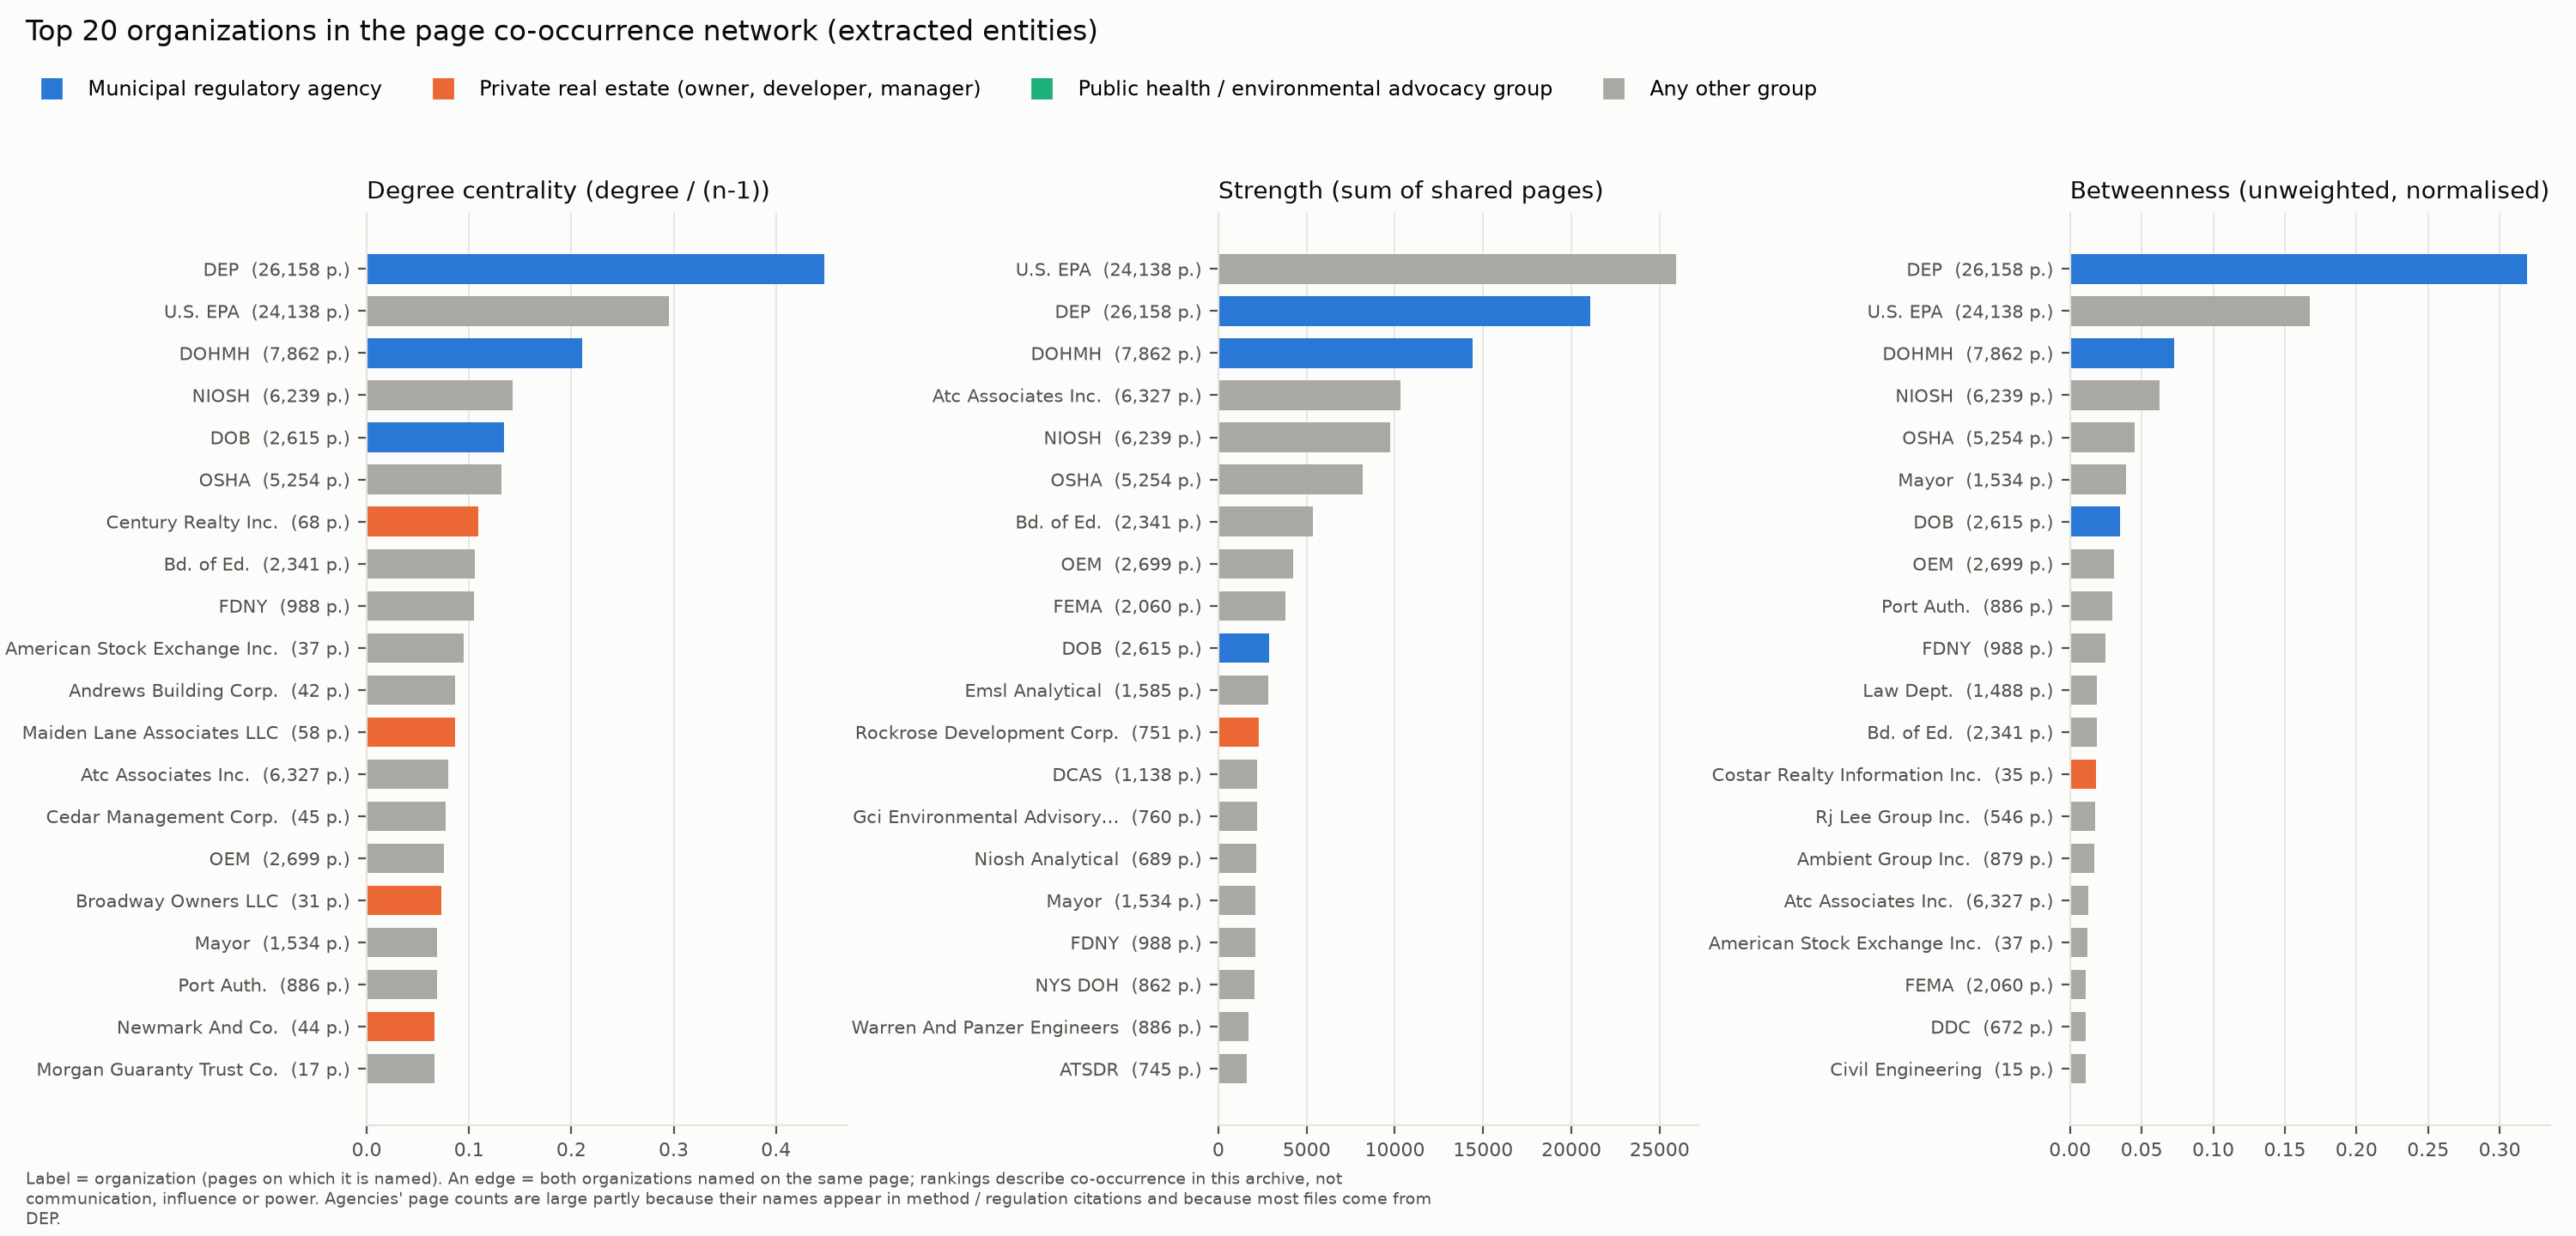

outputs/figures/network/fig2_hypothesis_groups.png


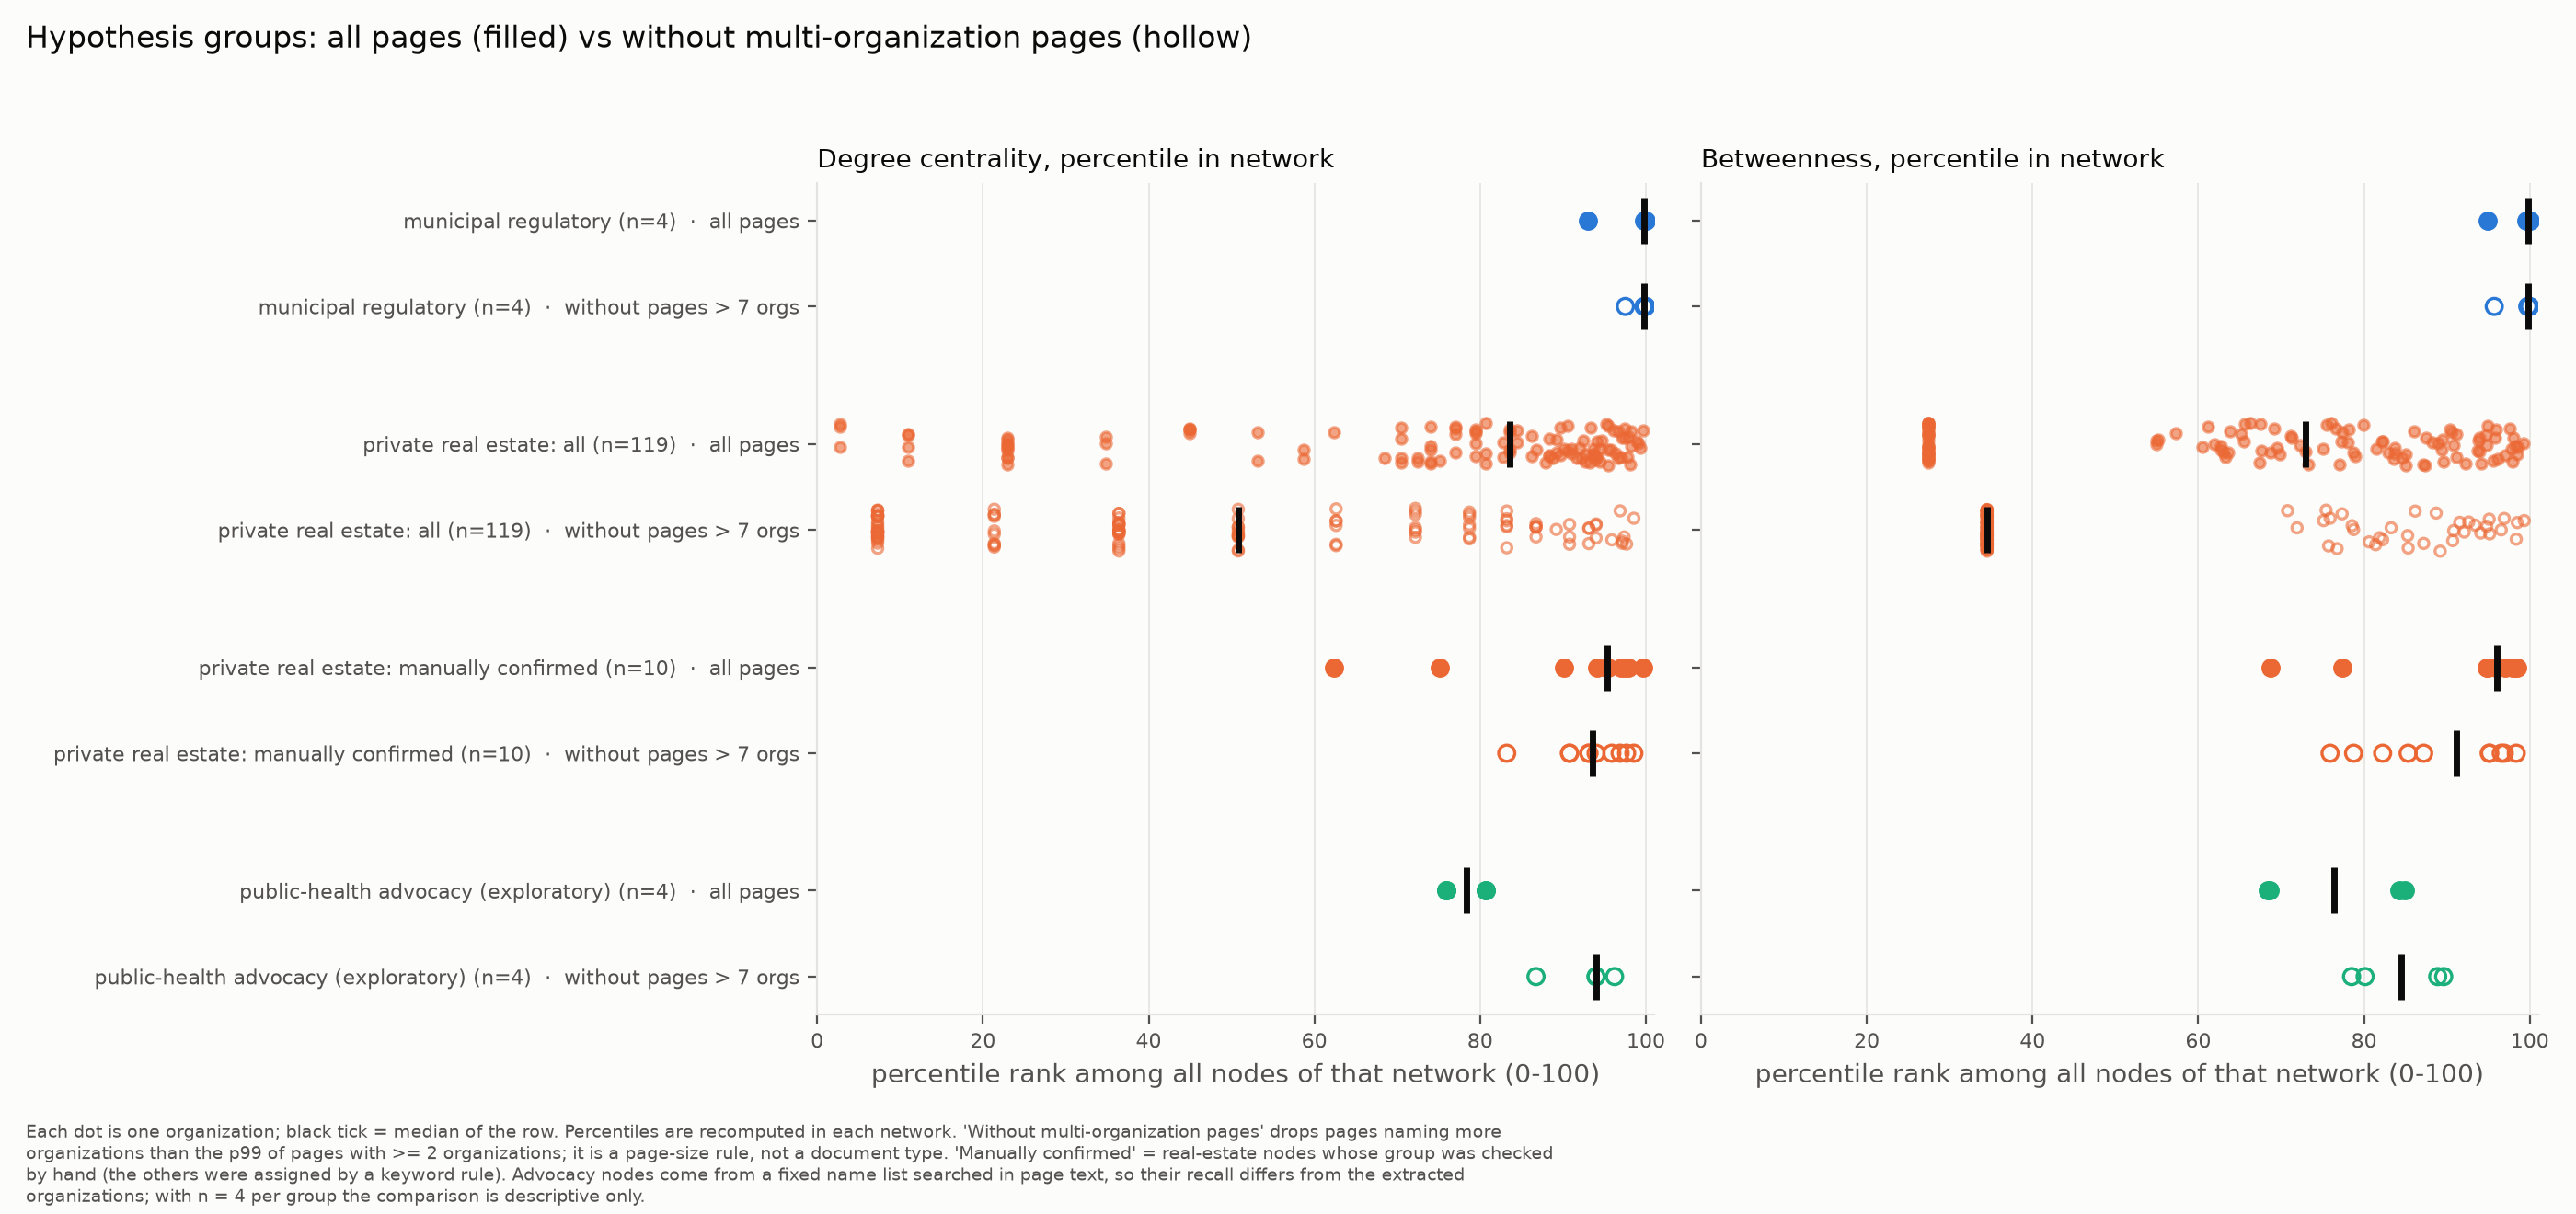

outputs/figures/network/fig3_frequency_vs_degree.png


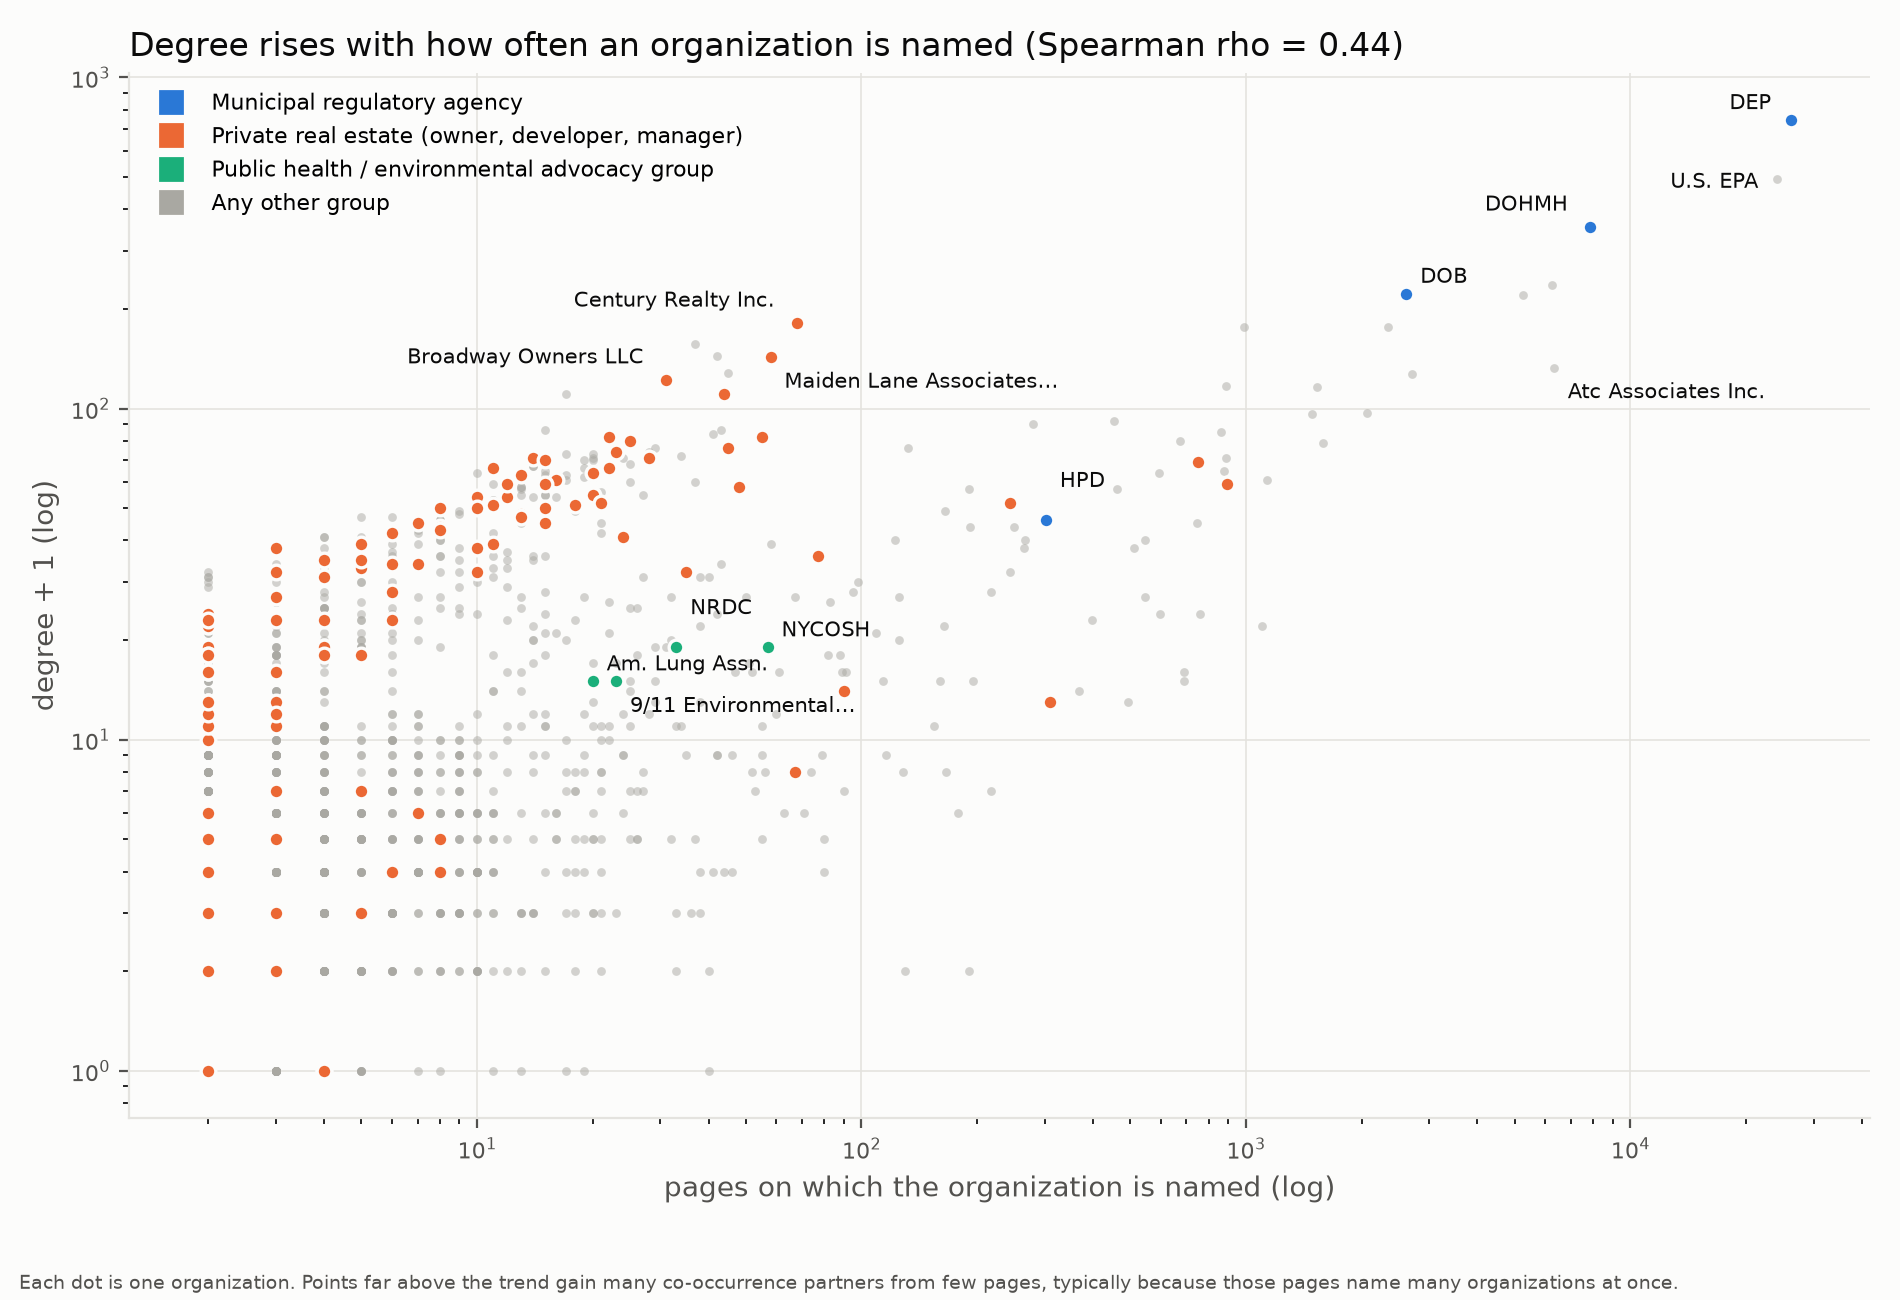

outputs/figures/network/fig4_network_subgraph.png


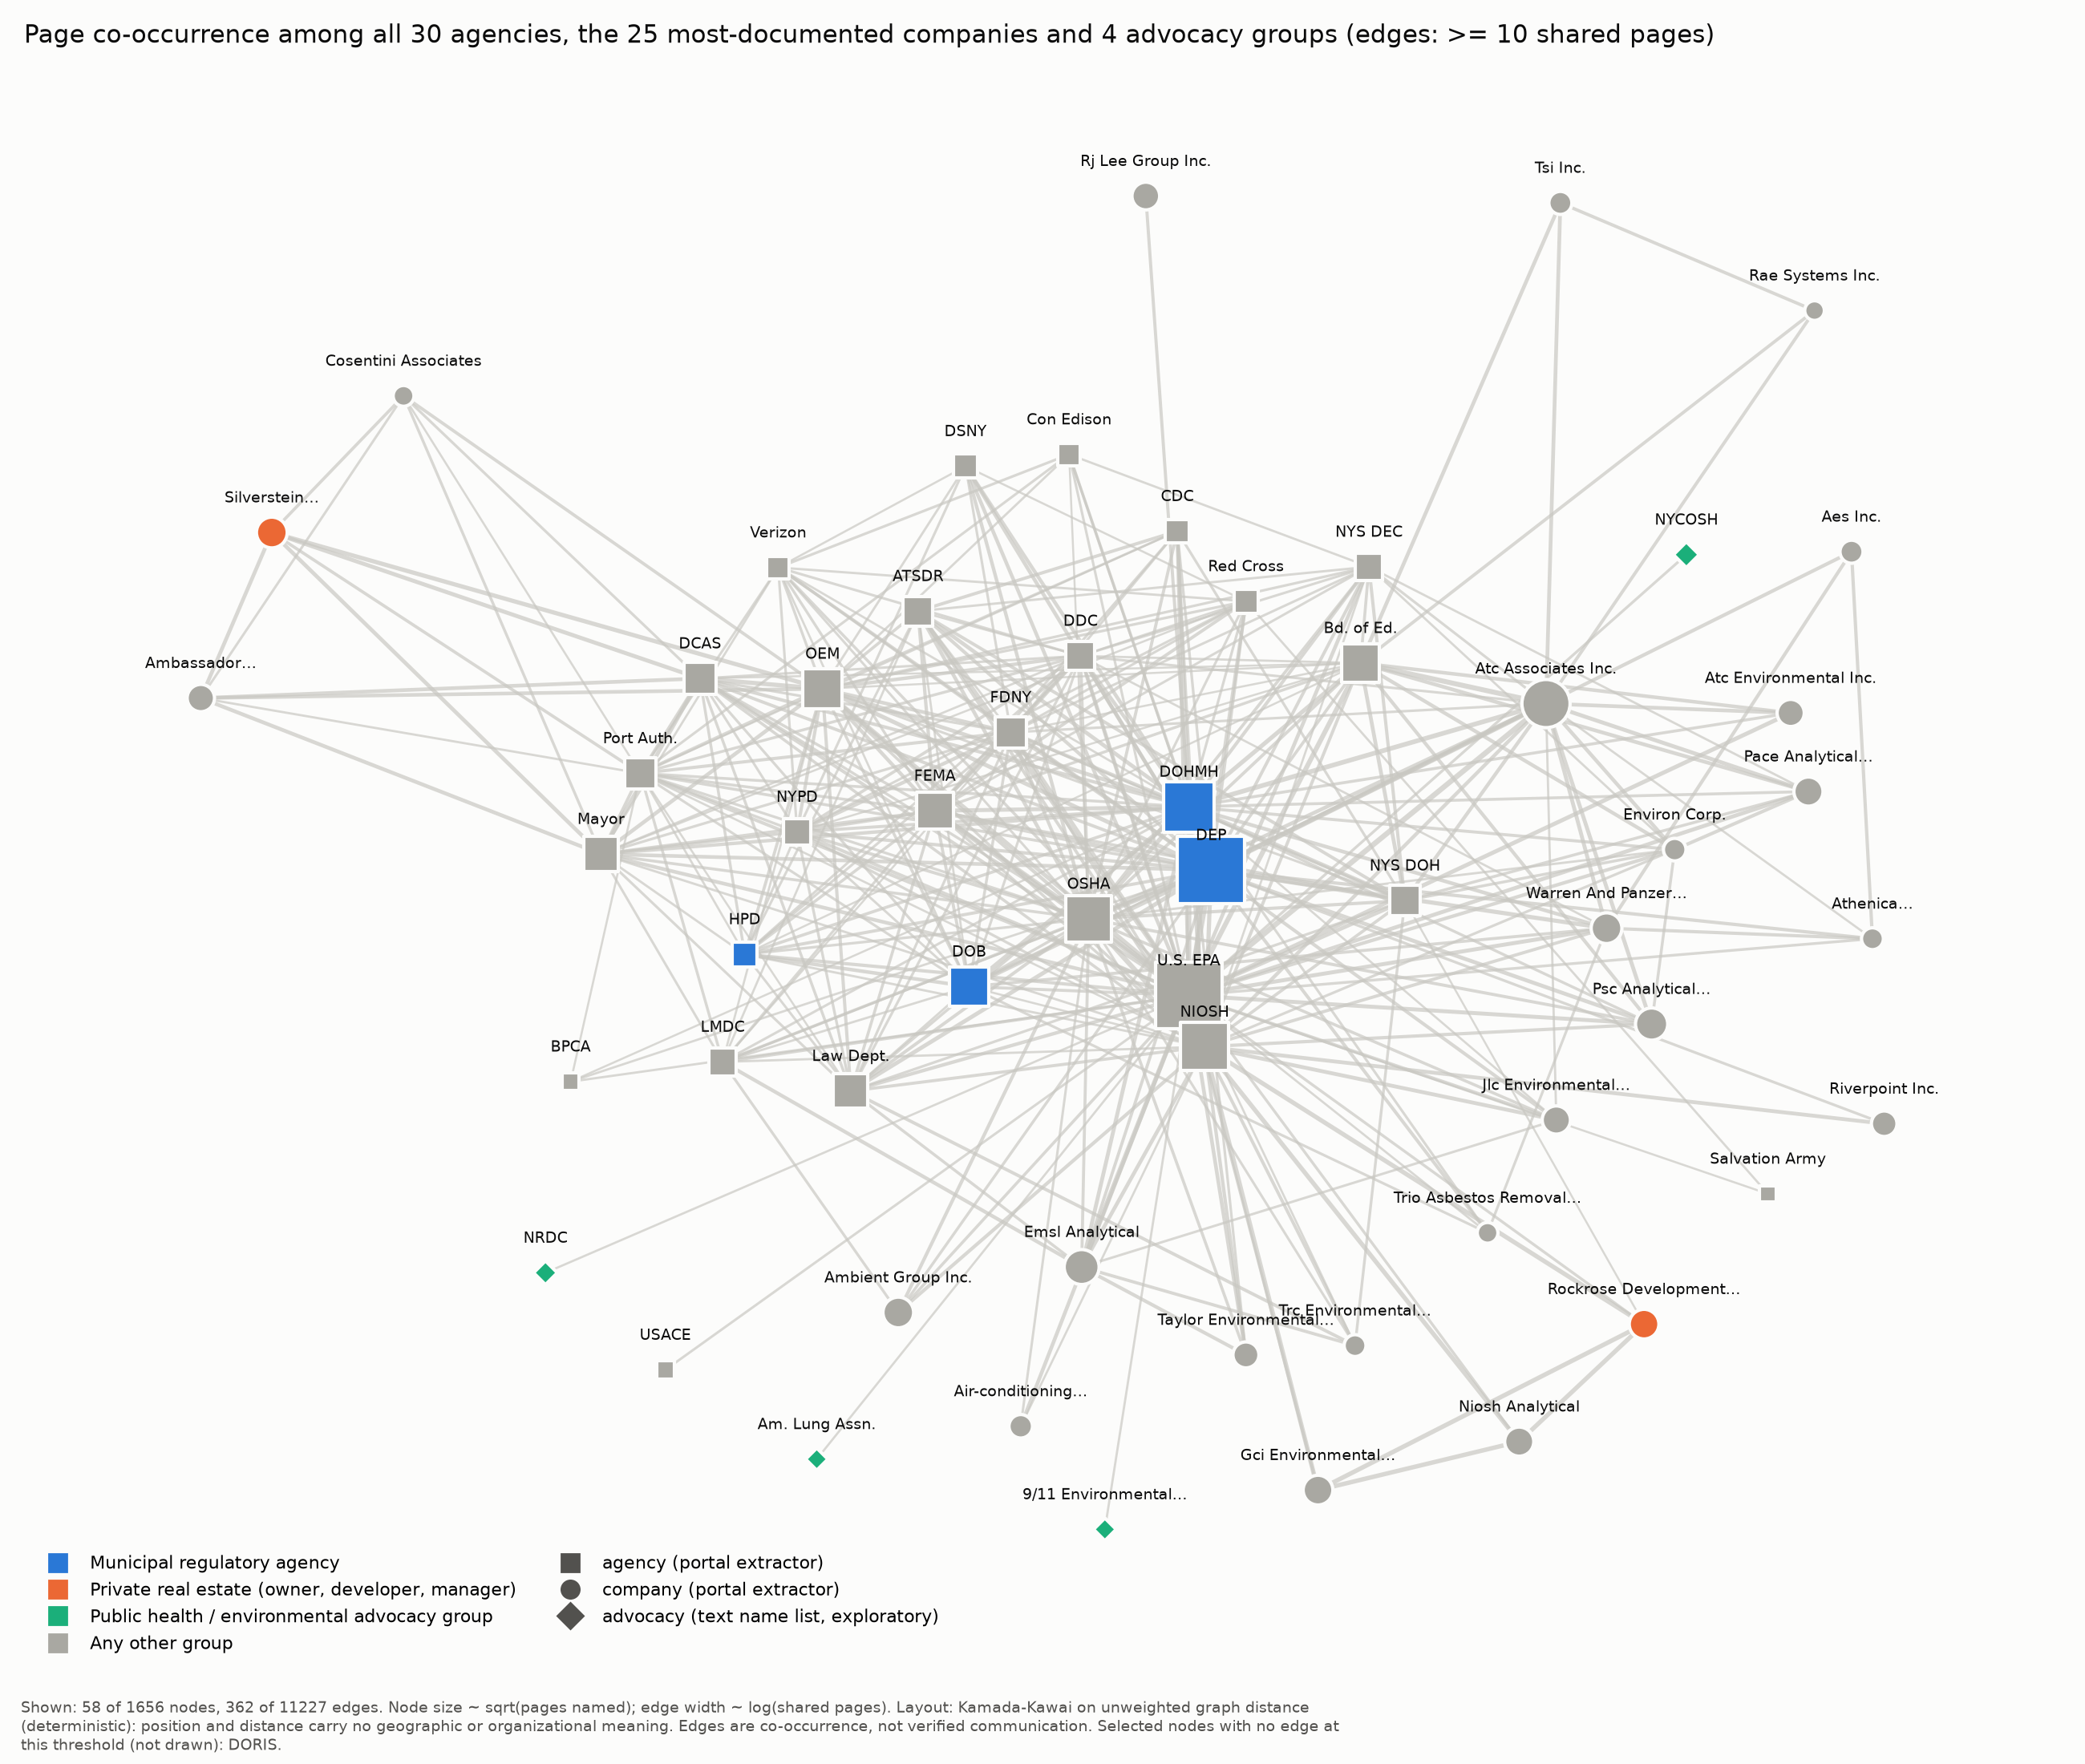

In [30]:
figures.top_ranking(main["nodes"])
figures.hypothesis_groups(hyp_nodes, scen[:2], ["all pages", f"without pages > {cutoff:.0f} orgs"])
lab = sup["nodes"]
label_ids = (set(lab.nlargest(4, "n_pages")["node_id"]) | set(lab.query("group == 'public_health_advocacy'")["node_id"])
             | set(lab.query("group == 'private_real_estate'").nlargest(3, "degree")["node_id"])
             | set(lab.query("group == 'municipal_regulatory'")["node_id"]))
figures.frequency_vs_degree(lab, label_ids)
figures.network_plot(sup)
for f in sorted(settings.FIGURES.glob("fig*.png")):
    print(f); display(Image(filename=str(f), width=900))

| Figure | Question it answers | What it cannot show |
|---|---|---|
| fig1 top centrality | Which organizations are most connected / most "between" in page co-occurrence? | Who communicated with whom, or who held power |
| fig2 hypothesis groups | Where does every node of the three hypothesis groups rank, with and without multi-organization pages, and for all vs hand-confirmed real estate? (study window and document network: tables only) | Significance; advocacy recall is not comparable; raw values (percentiles only) |
| fig3 frequency vs degree | Is centrality just how often a name appears? | Why an organization is named often |
| fig4 network subgraph | What the core of the co-occurrence structure looks like (30 agencies, 25 most-documented companies, 4 advocacy groups, edges ≥ 10 pages) | Geography or organizational distance (layout is arbitrary) |

## 7. Verification

In [31]:
verify.check_toy()

1. toy graph: all metrics match hand-computed values


In [32]:
run_outputs = settings.OUT / "nodes_main.csv"
if run_outputs.exists():
    nodes_out, edges_out = verify.check_outputs()
    verify.check_weights_from_raw(edges_out)
    verify.check_against_networkx_on_component(nodes_out, edges_out)
    verify.check_group_summaries()
    verify.check_window_filter()
    verify.check_pages_used_filter()
    # notebook results == saved tables used by the report
    saved = pd.read_csv(run_outputs).set_index("node_id")
    assert np.allclose(saved.loc[main["nodes"]["node_id"], "betweenness"], main["nodes"]["betweenness"])
    saved_sum = pd.read_csv(settings.OUT / "group_summary_by_scenario.csv")
    assert np.allclose(saved_sum["median"], summary["median"])
    print("notebook metrics and group summaries equal the saved tables in outputs/network/")
else:
    print("run `python -m src.analysis.network.run` to write the output tables, then re-run this cell")

2-3. 1652 nodes / 11166 edges: unique, ordered, no self-loops; evidence rows = sum C(k,2) = 99758; degree = edge count


4. 25 edge weights (10 heaviest + 15 random) match an independent recount from raw entity_mentions
5. agency-subgraph betweenness equals a direct networkx computation
6. baseline group medians match a direct recomputation; confirmed real estate = 10 nodes (subset of all 119); every scenario has the same nodes per group


7. study-window pages for 123 municipal / real-estate nodes match a recount from raw tables


8. n_pages_used under the page-size cut: toy (single-organization pages, isolates) correct; 127 hypothesis nodes match a recount from raw mentions
notebook metrics and group summaries equal the saved tables in outputs/network/


## 8. Summary — what we found, in plain English

1. **What the network is.** 1,652 organizations (30 agencies + 1,622 companies) linked when named on the same page: 11,166 edges, 91% of nodes in one component. It shows which organizations the archive *records together*, not who talked to whom. The main network is not filtered by date: 15% of dated documents predate 11 September 2001, and 11.9% of the pair evidence comes from outside the study window or from undated documents. Stored dates run 1908–2013; the two 1908 documents are suspected date errors.
2. **Who is central.** DEP is first on degree (0.45) and betweenness (0.32), followed by EPA and DOHMH — the top 3 in all four network variants (including study window only), with NIOSH always in the top 5.
3. **Frequency.** Centrality is moderately correlated with how often an organization is named (Spearman ρ = 0.44 for degree, 0.56 for betweenness), and the top agencies are by far the most named; 62% of documents come from DEP's own files. We cannot separate structural importance from being recorded often.
4. **Hypothesis 1.**
   * Municipal regulators vs advocacy groups: against the 4 advocacy organizations added by text search, every municipal regulator ranks higher in every variant, including the study-window-only network. Because the groups were identified differently, this is **a descriptive observation only and does not confirm the hypothesis**.
   * Private real estate > advocacy groups: **depends on which real-estate entities are counted.** For all 119 (mostly keyword-classified, rarely named) it does not hold once multi-organization pages are removed; for the 10 hand-confirmed firms it holds at baseline and in the study window; without multi-organization pages their median degree percentile is close and slightly lower (93.6 vs 94.0), and higher on betweenness. The confirmed firms are also named far more often, and classification and frequency cannot be separated. Not established.
   * Advocacy groups are **absent from the extracted entities**; the 4 found by text search are exploratory, so the comparison cannot be tested reliably.
5. **Next step.** Classify pages by type (correspondence, list, lab report) to separate document type from page size, and compare organizations named equally often.

Full write-up: `docs/network_analysis_report.md`.